### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Miguel Labra Lorenzana

* **Matrícula:** A01363726

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [ ]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numpy import mean, std

import os, warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
os.environ['PYTHONWARNINGS'] = 'ignore::FutureWarning,ignore::UserWarning'  

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (make_scorer, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)

from imblearn.metrics import geometric_mean_score, classification_report_imbalanced

**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [ ]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T

Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [3]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **1a)** En este conjunto de datos solo alrededor del 4.3% de los registros corresponden a derrames (28 de 659 en el conjunto de entrenamiento). Eso significa que un modelo que **nunca** detecte un derrame y siempre diga "no hay petróleo" ya tiene una exactitud cercana al 96%, sin haber aprendido absolutamente nada útil. La exactitud está dominada por la clase mayoritaria y por lo mismo esconde justo el error que más nos importa. Géron (2022, cap. 3) lo ilustra con un clasificador *dummy* que obtiene más del 90% de exactitud en un problema desbalanceado y concluye que "la exactitud generalmente no es la medida de desempeño preferida para los clasificadores, especialmente cuando se trabaja con conjuntos de datos sesgados (es decir, cuando algunas clases son mucho más frecuentes que otras)". <br><br>
La media geométrica, en cambio, se define como $G_{mean}=\sqrt{\text{Sensibilidad}\times\text{Especificidad}}$, donde la sensibilidad (recall) es $TP/(TP+FN)$ y la especificidad es $TN/(TN+FP)$ (Mukhiya & Ahmed, 2020, cap. 10). Al ser un producto, si el modelo falla por completo en alguna de las dos clases la métrica cae a cero: el modelo ingenuo que siempre predice "no derrame" tiene especificidad de 1 pero sensibilidad de 0, así que su G-mean es 0. Esto obliga al modelo a tener un buen desempeño **en ambas clases al mismo tiempo**, que es lo que buscamos cuando suponemos que los FP y FN son igualmente costosos.

* **1b)** Un Falso Positivo ocurre cuando el modelo indica que en ese pedazo de la imagen satelital **hay un derrame, pero en realidad no lo hay**. Kubat et al. (1998) explican que en las imágenes de radar existen muchos fenómenos que se parecen a una mancha de petróleo (*look-alikes*), como zonas de viento bajo, algas o corrientes, y son justamente los que generan estas falsas alarmas. Las implicaciones son principalmente operativas y económicas: enviar un helicóptero o embarcación a inspeccionar sin necesidad, consumir combustible y horas-hombre, distraer recursos que podrían usarse en una alerta real y, si se repiten mucho, generar "fatiga de alertas" en el personal, que empieza a desconfiar del sistema y a ignorar sus avisos.

* **1c)** Un Falso Negativo ocurre cuando **sí hay un derrame y el modelo lo clasifica como océano limpio**. Es el error más grave en este contexto: el derrame no se atiende a tiempo, el petróleo se sigue extendiendo, aumenta el daño ecológico (fauna, costas, pesca), los costos de limpieza crecen mientras más tarde se detecta, se pierde la oportunidad de identificar al barco o fuente responsable y hay consecuencias legales y de reputación para la autoridad encargada de vigilar. Géron (2022, cap. 3) usa un ejemplo análogo: un detector de robos en tiendas puede tener solo 30% de precisión siempre y cuando tenga 99% de recall, porque es preferible revisar algunas falsas alarmas a dejar pasar los casos reales.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [4]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


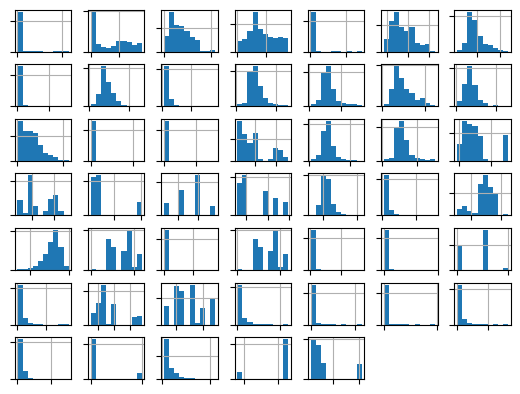

In [5]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [6]:
Xtrain.info()

<class 'pandas.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25    659 non-

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **2a)** La transformación Yeo-Johnson (Yeo & Johnson, 2000) es una familia de transformaciones de potencia cuyo objetivo es hacer que la distribución de una variable sea más simétrica y parecida a una normal, reduciendo el sesgo (*skewness*) y el efecto de colas largas.

* **2b)** La diferencia principal es el dominio: **Box-Cox solo funciona con valores estrictamente positivos** ($y>0$), porque involucra $\ln(y)$ y potencias de $y$. Yeo-Johnson extiende la idea para aceptar **ceros y valores negativos**: para $y\ge0$ es básicamente una Box-Cox aplicada a $y+1$ y para $y<0$ aplica una Box-Cox "reflejada" sobre $1-y$ con potencia $2-\lambda$. En nuestro conjunto de datos hay columnas con valores negativos (`f_26`, `f_28`, `f_30` y `f_31`) y otras con ceros (por ejemplo `f_5`, `f_33` o `f_41`), así que Box-Cox no se podría aplicar directamente sin sumar una constante arbitraria a cada columna; por eso Yeo-Johnson es la opción natural para este preprocesamiento.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [7]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* **3a)** Probé las cinco estrategias del `DummyClassifier` con `n_splits` = 3, 5, 7 y 10 (ver la tabla de la celda de exploración más abajo). Las estrategias `most_frequent`, `prior` y `constant` dan una G-mean de **0** en todos los casos, porque siempre predicen una sola clase, así que una de las dos tasas (sensibilidad o especificidad) es cero. `stratified` tampoco sirve como referencia porque predice positivos en la proporción de la clase minoritaria (~4%) y casi nunca acierta a un derrame, quedando en valores cercanos a 0. La estrategia más adecuada para la G-mean es **`uniform`**: predice cada clase con probabilidad 0.5, lo que da en teoría una sensibilidad y especificidad cercanas a 0.5.
Para `n_splits` me quedé con **3**. El conjunto de entrenamiento solo tiene 28 derrames; con 3 particiones cada pliegue de validación tiene ~9 positivos, mientras que con 10 particiones quedan apenas 2 o 3, y con tan pocos casos un solo acierto o error mueve muchísimo la métrica. Eso se ve en los resultados: con `uniform` la desviación estándar fue 0.067 con 3 splits, contra 0.137 con 5 y 0.163 con 10. Es decir, 3 particiones dan la estimación más estable del modelo base, que es lo que queremos para un umbral de referencia.

* **3b)** Con `strategy='uniform'` y `n_splits=3`, el valor de referencia es **G-mean ≈ 0.551** (std ≈ 0.067). Cualquier modelo que no supere este valor lo consideraremos subentrenado.

* **3c)** Con la exactitud, el modelo ingenuo más difícil de superar es `most_frequent` (siempre predice "no hay derrame"), y su exactitud es **≈ 0.958**, es decir, la proporción de la clase mayoritaria. Su matriz de confusión en entrenamiento es:

|                 | Predicho: no derrame | Predicho: derrame |
|-----------------|:-------------------:|:-----------------:|
| **Real: no derrame** | 631 (TN) | 0 (FP) |
| **Real: derrame**    | 28 (FN)  | 0 (TP) |

O sea, "acierta" el 95.8% de las veces sin detectar **ni uno** de los 28 derrames, y su G-mean es 0. Es exactamente el caso del clasificador *dummy* que describe Géron (2022, cap. 3): una exactitud que parece excelente pero que solo refleja el desbalance de las clases.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [8]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


In [9]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'uniform'

mi_nsplits = 3


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))


Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.65229372 0.57445626 0.4530905  0.50796707 0.52915026 0.60858062
 0.45201556 0.6172134  0.56061191]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.551, std=(0.067)


In [10]:
# Exploración de combinaciones de "strategy" y "n_splits" con la G-mean (apoyo para el inciso 3a).
# Nota: 'constant' requiere indicar la clase; usamos constant=1 (siempre predice derrame).
filas = []
for est in ['most_frequent', 'prior', 'stratified', 'uniform', 'constant']:
  for k in [3, 5, 7, 10]:
    cv_tmp = RepeatedStratifiedKFold(n_splits=k, n_repeats=3, random_state=7)
    extra = {'constant': 1} if est == 'constant' else {}
    pD = Pipeline(steps=[('ct', columnasTransformer), ('Dummy', DummyClassifier(strategy=est, random_state=7, **extra))])
    sc = cross_val_score(pD, Xtrain, ytrain, scoring=mi_metrica, cv=cv_tmp)
    filas.append([est, k, round(sc.mean(), 3), round(sc.std(), 3)])

tabla_dummy = pd.DataFrame(filas, columns=['strategy', 'n_splits', 'G-mean (media)', 'G-mean (std)'])
tabla_dummy.pivot(index='strategy', columns='n_splits', values=['G-mean (media)', 'G-mean (std)'])


G-mean (media)                      G-mean (std)                \
n_splits                  3      5      7      10           3      5      7    
strategy                                                                       
constant               0.000  0.000  0.000  0.000        0.000  0.000  0.000   
most_frequent          0.000  0.000  0.000  0.000        0.000  0.000  0.000   
prior                  0.000  0.000  0.000  0.000        0.000  0.000  0.000   
stratified             0.071  0.054  0.000  0.000        0.133  0.138  0.000   
uniform                0.551  0.508  0.489  0.493        0.067  0.137  0.081   

                      
n_splits          10  
strategy              
constant       0.000  
most_frequent  0.000  
prior          0.000  
stratified     0.000  
uniform        0.163

Exactitud del modelo ingenuo (most_frequent): 0.958, std=(0.002)



Matriz de confusión del modelo ingenuo (Train, filas=real, columnas=predicción):
 [[631   0]
 [ 28   0]]
G-mean de este mismo modelo ingenuo: 0.000


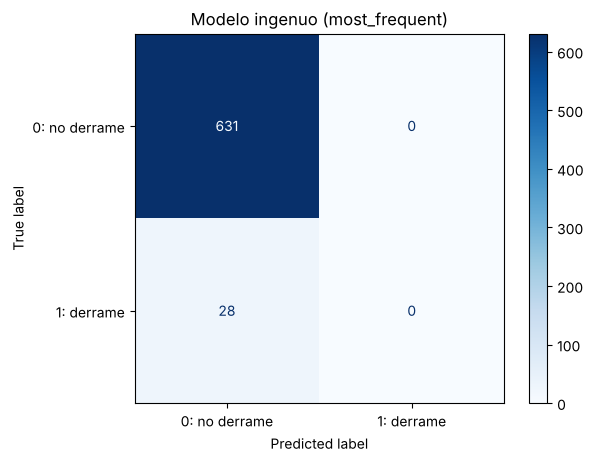

In [11]:
# Inciso 3c: modelo base con la métrica de exactitud (accuracy).
# Para la exactitud la estrategia ingenua más difícil de superar es 'most_frequent':
# siempre predice la clase mayoritaria (0 = no hay derrame).
cvA = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)
pipelineA = Pipeline(steps=[('ct', columnasTransformer), ('Dummy', DummyClassifier(strategy='most_frequent'))])
scoresA = cross_val_score(pipelineA, Xtrain, ytrain, scoring='accuracy', cv=cvA)
print('Exactitud del modelo ingenuo (most_frequent): %.3f, std=(%.3f)' % (mean(scoresA), std(scoresA)))

# Matriz de confusión del modelo ingenuo (predicciones fuera de muestra con validación cruzada estratificada):
from sklearn.model_selection import StratifiedKFold
ytrain_dummy = cross_val_predict(pipelineA, Xtrain, ytrain, cv=StratifiedKFold(n_splits=mi_nsplits, shuffle=True, random_state=7))
cm_dummy = confusion_matrix(ytrain, ytrain_dummy)
print('\nMatriz de confusión del modelo ingenuo (Train, filas=real, columnas=predicción):\n', cm_dummy)
print('G-mean de este mismo modelo ingenuo: %.3f' % geometric_mean_score(ytrain, ytrain_dummy))
ConfusionMatrixDisplay(cm_dummy, display_labels=['0: no derrame', '1: derrame']).plot(cmap='Blues')
plt.title('Modelo ingenuo (most_frequent)')
plt.show()


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:


LR
Exactitud: >> 0.947 (0.013)
G-mean: >> 0.653 (0.119)



LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)



RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)



EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)



kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



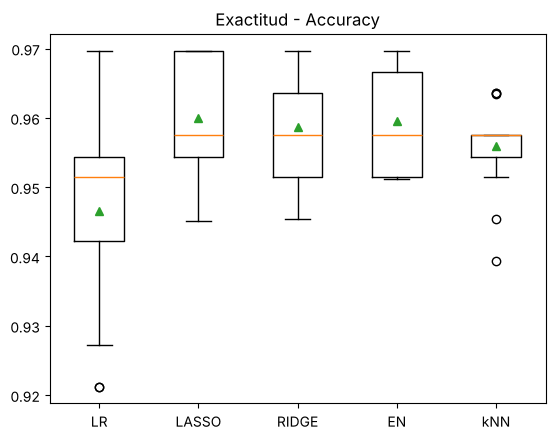

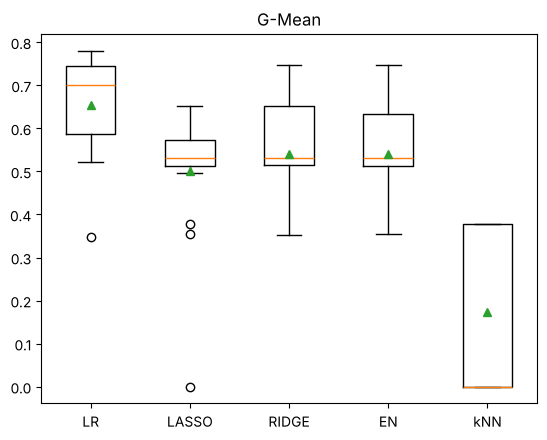

In [12]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* **4a)** El umbral del modelo base con exactitud es ≈ 0.958. **LR (0.947) y kNN (0.956)** quedan por debajo, así que están subentrenados. LASSO (0.960), RIDGE (0.959) y EN (0.960) apenas lo superan por unas milésimas, una diferencia mucho menor que su propia desviación estándar (~0.008), así que en la práctica se comportan igual que el modelo que siempre dice "no hay derrame". Esto ya es una señal de que la exactitud no nos dice si el modelo aprendió algo.

* **4b)** Con la G-mean el umbral es ≈ 0.551. Quedan subentrenados **kNN (0.174), LASSO (0.501), RIDGE (0.541) y EN (0.540)**. El único que lo supera es **LR sin regularización (0.653)**, aunque con una desviación estándar alta (0.119). Lo interesante es que los modelos regularizados, que eran "los mejores" según la exactitud, son de los peores con la G-mean: con los valores por defecto (`C=1`, sin pesos de clase) la frontera de decisión se va hacia la clase mayoritaria y detectan muy pocos derrames. kNN es el peor caso, porque con 47 variables los vecinos más cercanos de casi cualquier punto son de la clase mayoritaria.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

In [13]:
# Búsqueda de hiperparámetros con GridSearchCV (soporte del Ejercicio 5).
# Tarda unos minutos. Se usa la misma partición de validación cruzada y la métrica G-mean.

cv_gs = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
Cs = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]

busquedas = {
  'LR':    (LogisticRegression(penalty=None, max_iter=5000, random_state=1),
            {'m__class_weight': [None, 'balanced']}),
  'LASSO': (LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000, random_state=1),
            {'m__C': Cs, 'm__class_weight': [None, 'balanced']}),
  'RIDGE': (LogisticRegression(penalty='l2', max_iter=5000, random_state=1),
            {'m__C': Cs, 'm__class_weight': [None, 'balanced']}),
  'EN':    (LogisticRegression(penalty='elasticnet', solver='saga', max_iter=10000, random_state=1),
            {'m__C': [0.01, 0.03, 0.1, 0.3, 1], 'm__l1_ratio': [0.2, 0.5, 0.8], 'm__class_weight': ['balanced']}),
  'kNN':   (KNeighborsClassifier(),
            {'m__n_neighbors': [1, 3, 5, 7], 'm__weights': ['uniform', 'distance'], 'm__p': [1, 2]}),
}

for nombre, (modelo, malla) in busquedas.items():
  gs = GridSearchCV(Pipeline(steps=[('ct', columnasTransformer), ('m', modelo)]),
                    malla, scoring=mi_metrica, cv=cv_gs, n_jobs=-1)
  gs.fit(Xtv, np.ravel(ytv))
  print('%-6s mejor G-mean=%.3f (std=%.3f) con %s' % (nombre, gs.best_score_,
        gs.cv_results_['std_test_score'][gs.best_index_], gs.best_params_))


LR     mejor G-mean=0.759 (std=0.123) con {'m__class_weight': 'balanced'}


LASSO  mejor G-mean=0.837 (std=0.052) con {'m__C': 0.1, 'm__class_weight': 'balanced'}


RIDGE  mejor G-mean=0.817 (std=0.106) con {'m__C': 0.01, 'm__class_weight': 'balanced'}


EN     mejor G-mean=0.845 (std=0.046) con {'m__C': 0.03, 'm__class_weight': 'balanced', 'm__l1_ratio': 0.8}


kNN    mejor G-mean=0.497 (std=0.101) con {'m__n_neighbors': 1, 'm__p': 1, 'm__weights': 'uniform'}


Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


LR
G-mean: >> 0.759 (0.123)



LASSO
G-mean: >> 0.837 (0.052)



RIDGE
G-mean: >> 0.817 (0.106)



EN
G-mean: >> 0.845 (0.046)



kNN
G-mean: >> 0.497 (0.101)



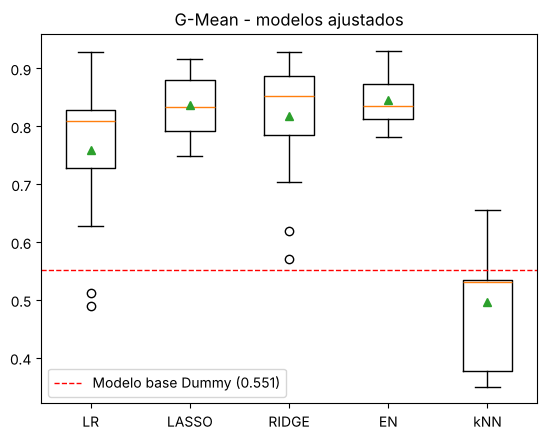

In [ ]:
# 5)

print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++

def mis_modelos_ajustados():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None,
                                    class_weight='balanced',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('LR')

  modelos.append(LogisticRegression(penalty='l1',
                                    solver='liblinear',
                                    C=0.1,
                                    class_weight='balanced',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('LASSO')

  modelos.append(LogisticRegression(penalty='l2',
                                    C=0.01,
                                    class_weight='balanced',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',
                                    solver='saga',
                                    C=0.03,
                                    l1_ratio=0.8,
                                    class_weight='balanced',
                                    max_iter=10000,
                                    random_state=1))
  nombres.append('EN')

  # kNN no tiene el argumento class_weight; ajustamos k, la métrica de distancia (p) y los pesos.
  modelos.append(KNeighborsClassifier(n_neighbors=1,
                                      p=1,
                                      weights='uniform'))
  nombres.append('kNN')

  return modelos, nombres


modelos, nombres = mis_modelos_ajustados()
resultados_aj = list()

for i in range(len(modelos)):
  pipeline = Pipeline(steps=[('ct', columnasTransformer), ('m', modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring=mi_metrica, cv=cv1)
  resultados_aj.append(scores)
  print(nombres[i])
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores), np.nanstd(scores)))
  print()

plt.boxplot(resultados_aj, tick_labels=nombres, showmeans=True)
plt.axhline(0.551, color='red', linestyle='--', linewidth=1, label='Modelo base Dummy (0.551)')
plt.title("G-Mean - modelos ajustados")
plt.legend(loc='lower left')
plt.show()

# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [ ]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# Comparamos los mejores candidatos de la validación cruzada entrenando con Xtrain y evaluando con Xval,
# para verificar que la brecha Train-Val de la G-mean no supere el 3%.

candidatos = {
  'LASSO C=0.1':     LogisticRegression(penalty='l1', solver='liblinear', C=0.1, class_weight='balanced', max_iter=5000, random_state=1),
  'EN C=0.03 r=0.8': LogisticRegression(penalty='elasticnet', solver='saga', C=0.03, l1_ratio=0.8, class_weight='balanced', max_iter=10000, random_state=1),
  'RIDGE C=0.01':    LogisticRegression(penalty='l2', C=0.01, class_weight='balanced', max_iter=5000, random_state=1),
  'LASSO C=1':       LogisticRegression(penalty='l1', solver='liblinear', C=1, class_weight='balanced', max_iter=5000, random_state=1),
  'LASSO C=2':       LogisticRegression(penalty='l1', solver='liblinear', C=2, class_weight='balanced', max_iter=5000, random_state=1),
  'RIDGE C=2':       LogisticRegression(penalty='l2', C=2, class_weight='balanced', max_iter=5000, random_state=1),
}
cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
filas = []
for nom, mod in candidatos.items():
  p = Pipeline(steps=[('ct', columnasTransformer), ('m', mod)])
  g_cv = cross_val_score(p, Xtv, np.ravel(ytv), scoring=mi_metrica, cv=cv1)
  p.fit(Xtrain, np.ravel(ytrain))
  g_tr = geometric_mean_score(np.ravel(ytrain), p.predict(Xtrain))
  g_va = geometric_mean_score(np.ravel(yval), p.predict(Xval))
  filas.append([nom, g_cv.mean(), g_cv.std(), g_tr, g_va, abs(g_tr - g_va)])
display(pd.DataFrame(filas, columns=['modelo', 'G-mean CV', 'std CV', 'G-mean Train', 'G-mean Val', '|Train-Val|']).round(4))

# Mejor modelo: Regresión logística con penalización L1 (LASSO), C=2 y pesos balanceados.
mejor_modelo = Pipeline(steps=[('ct', columnasTransformer),
                               ('m', LogisticRegression(penalty='l1',
                                                        solver='liblinear',
                                                        C=2,
                                                        class_weight='balanced',
                                                        max_iter=5000,
                                                        random_state=1))])
mejor_modelo.fit(Xtrain, np.ravel(ytrain))

ytrain_hat = mejor_modelo.predict(Xtrain)

yval_hat = mejor_modelo.predict(Xval)

print('Diferencia |Train - Val| de la G-mean: %.2f%%\n' % (100*abs(geometric_mean_score(np.ravel(ytrain), ytrain_hat) - geometric_mean_score(np.ravel(yval), yval_hat))))

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

,modelo,G-mean CV,std CV,G-mean Train,G-mean Val,|Train-Val|
0,LASSO C=0.1,0.8373,0.0523,0.8611,0.9341,0.0731
1,EN C=0.03 r=0.8,0.8448,0.0460,0.8537,0.9273,0.0736
2,RIDGE C=0.01,0.8173,0.1058,0.8701,0.9273,0.0572
3,LASSO C=1,0.8044,0.0808,0.9267,0.9443,0.0176
4,LASSO C=2,0.8134,0.0861,0.9546,0.9477,0.0069
5,RIDGE C=2,0.8004,0.0778,0.9300,0.9510,0.0210


Diferencia |Train - Val| de la G-mean: 0.69%

G-mean del mejor modelo-Train: 0.9546
G-mean del mejor modelo-Val: 0.9477

Exactitud del mejor modelo-Train: 0.9150
Exactitud del mejor modelo-Val: 0.9030

Matriz de Confusión con Validación:
 [[141  16]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.85454545 0.0969697 ]
 [0.         0.04848485]]


Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **6b)** En la celda Código-1 los modelos logísticos tenían exactitudes de ~0.96, y ahora el mejor modelo tiene ~0.90 en validación. La razón es el argumento `class_weight='balanced'`: le da a cada derrame un peso aproximadamente 12 veces mayor que a un caso sin derrame ($n/(2\,n_{positivos})$), lo que desplaza la frontera de decisión hacia la clase mayoritaria. El modelo ahora prefiere "levantar la mano" ante cualquier imagen sospechosa: detecta los 8 derrames de validación (antes se le escapaban la mayoría), pero a cambio genera algunas falsas alarmas sobre la clase "no derrame". Como esa clase es el 95% de los datos, cada falso positivo baja la exactitud, aunque el modelo sea mucho más útil. Es el *trade-off* precisión/recall que describe Géron (2022, cap. 3): no se pueden subir las dos al mismo tiempo, y aquí sacrificamos precisión (y exactitud) a cambio de recall. Esto confirma lo del Ejercicio 1: una menor exactitud no significa un peor modelo cuando las clases están desbalanceadas.

<br>

**Sobre la selección del mejor modelo (6a):** en la validación cruzada del Ejercicio 5 los mejores valores fueron EN (C=0.03) y LASSO (C=0.1), pero al entrenarlos con `Xtrain` y evaluarlos con `Xval` su G-mean de validación quedaba entre 6% y 7% **por encima** de la de entrenamiento, lo que indica que con tanta regularización el modelo todavía tiene sesgo alto, y además ese valor de validación depende de solo 8 derrames. Con una regularización más ligera, **LASSO con `C=2` y `class_weight='balanced'`**, la G-mean de validación cruzada se mantiene en el mismo nivel (~0.81, dentro de una desviación estándar de los mejores), la brecha entre entrenamiento (≈0.955) y validación (≈0.948) es menor al 1%, y por lo tanto no está ni sub- ni sobreentrenado. Además, la penalización L1 tiende a llevar a cero los pesos de las variables menos importantes, es decir, hace una selección automática de variables (Géron, 2022, cap. 4), lo que equivale a suponer una distribución a priori de Laplace sobre los parámetros (Deisenroth et al., 2020, sec. 9.2, p. 316). Esto es útil con 47 variables y tan pocos casos positivos.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

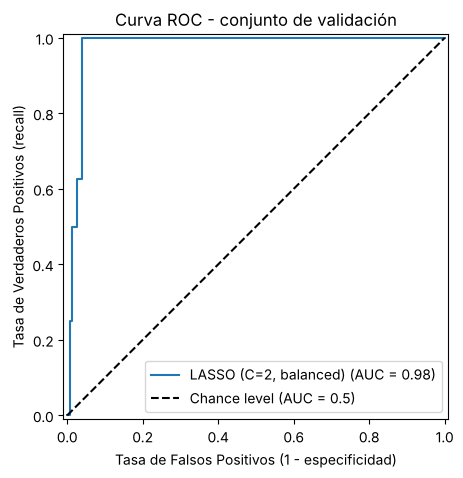

In [16]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(mejor_modelo, Xval, np.ravel(yval), name='LASSO (C=2, balanced)',
                               plot_chance_level=True, ax=ax)
ax.set_title('Curva ROC - conjunto de validación')
ax.set_xlabel('Tasa de Falsos Positivos (1 - especificidad)')
ax.set_ylabel('Tasa de Verdaderos Positivos (recall)')
plt.show()

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

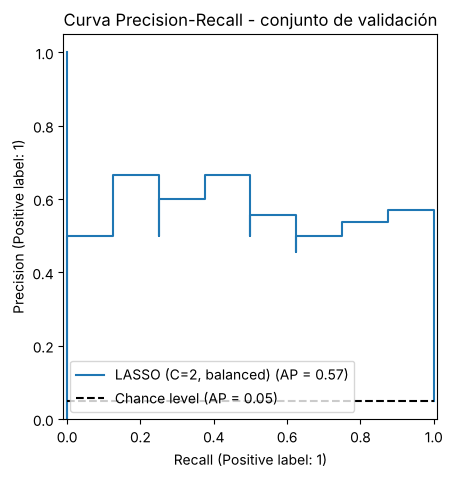

Nivel de azar (proporción de positivos en Val): 0.048


In [17]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_estimator(mejor_modelo, Xval, np.ravel(yval), name='LASSO (C=2, balanced)',
                                      plot_chance_level=True, ax=ax)
ax.set_title('Curva Precision-Recall - conjunto de validación')
ax.set_ylim(0, 1.05)
plt.show()
print('Nivel de azar (proporción de positivos en Val): %.3f' % np.ravel(yval).mean())

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **6e)** La curva ROC da un **AUC ≈ 0.98** contra 0.5 del nivel de azar, lo que a primera vista indica un modelo casi perfecto para ordenar las imágenes: en la gran mayoría de los casos asigna una probabilidad más alta a un derrame real que a una imagen limpia. Sin embargo, la ROC tiende a ser optimista en problemas desbalanceados: el eje X es la tasa de falsos positivos, $FP/(FP+TN)$, y como hay 157 imágenes sin derrame, 16 falsas alarmas apenas representan un 10%. <br><br>
La curva Precision-Recall cuenta una historia más realista. Su área (precisión promedio, AP) es **≈ 0.57**, contra un nivel de azar de solo **≈ 0.05** (la proporción de derrames en validación), es decir, el modelo es más de 10 veces mejor que adivinar. Pero también muestra sus límites: con el umbral predeterminado de 0.5 se recupera el 100% de los derrames con una precisión de solo 0.33 (por cada derrame real hay unas dos falsas alarmas), y aun en el mejor punto de la curva con recall de 1 la precisión no pasa de ≈0.57. Además, la curva nunca se acerca a la esquina superior derecha porque algunas imágenes sin derrame reciben probabilidades muy altas (cercanas a 1)
En el contexto del problema, mi conclusión es que el modelo es muy bueno como **filtro** para priorizar qué imágenes revisar (ningún derrame se le escapó en validación), pero no lo suficientemente preciso para mandar helicópteros de forma automática sin una verificación previa. También hay que tomar estos números con cautela, ya que el conjunto de validación solo tiene 8 derrames.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [18]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.90      1.00      0.95      0.95      0.89       157
class 1:oil-spill       0.33      1.00      0.90      0.50      0.95      0.91         8

      avg / total       0.97      0.90      1.00      0.92      0.95      0.89       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





Umbrales con el costo mínimo: de 0.76 a 0.77
Umbral óptimo seleccionado: 0.76  ->  Costo total = $90,000 USD
Costo con el umbral predeterminado 0.5: $240,000 USD


,umbral,TP,FP,FN,TN,costo_total
0,0.10,8,36,0,121,540000
5,0.15,8,31,0,126,465000
10,0.20,8,26,0,131,390000
15,0.25,8,24,0,133,360000
20,0.30,8,23,0,134,345000
25,0.35,8,22,0,135,330000
30,0.40,8,19,0,138,285000
35,0.45,8,19,0,138,285000
40,0.50,8,16,0,141,240000
45,0.55,8,14,0,143,210000


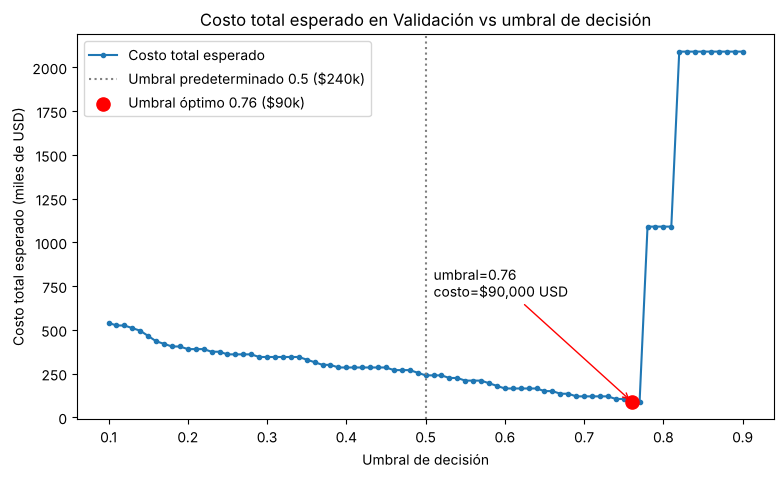

In [ ]:
# Respuesta Ejercicio 7a y 7b:

COSTO_FN = 1_000_000   # derrame no detectado
COSTO_FP = 15_000      # falsa alarma (vuelo de inspección)

def costo_total_esperado(y_real, probas, umbrales, costo_fn=COSTO_FN, costo_fp=COSTO_FP):
    """Calcula el costo total de los errores para cada umbral de decisión.
    Regresa un DataFrame con el umbral, FP, FN y el costo total asociado."""
    y_real = np.ravel(y_real)
    filas = []
    for u in umbrales:
        y_pred = (probas >= u).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
        filas.append({'umbral': round(u, 2), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                      'costo_total': fn*costo_fn + fp*costo_fp})
    return pd.DataFrame(filas)

# Probabilidades de la clase positiva en Validación con el mejor modelo:
proba_val = mejor_modelo.predict_proba(Xval)[:, 1]
umbrales = np.round(np.arange(0.10, 0.901, 0.01), 2)
tabla_costos = costo_total_esperado(yval, proba_val, umbrales)


costo_min = tabla_costos['costo_total'].min()
empates = tabla_costos[tabla_costos['costo_total'] == costo_min]
umbral_opt = empates['umbral'].min()
print('Umbrales con el costo mínimo: de %.2f a %.2f' % (empates['umbral'].min(), empates['umbral'].max()))
print('Umbral óptimo seleccionado: %.2f  ->  Costo total = $%s USD' % (umbral_opt, f'{costo_min:,.0f}'))
c05 = tabla_costos.loc[tabla_costos['umbral'] == 0.5, 'costo_total'].item()
print('Costo con el umbral predeterminado 0.5: $%s USD' % f'{c05:,.0f}')
display(tabla_costos.iloc[::5])

# 7b) Gráfica Costo total vs umbral
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_costos['umbral'], tabla_costos['costo_total']/1e3, marker='.', label='Costo total esperado')
ax.axvline(0.5, color='gray', linestyle=':', label='Umbral predeterminado 0.5 ($%sk)' % f'{c05/1e3:,.0f}')
ax.scatter([umbral_opt], [costo_min/1e3], color='red', s=90, zorder=3,
           label='Umbral óptimo %.2f ($%sk)' % (umbral_opt, f'{costo_min/1e3:,.0f}'))
ax.annotate('umbral=%.2f\ncosto=$%s USD' % (umbral_opt, f'{costo_min:,.0f}'),
            xy=(umbral_opt, costo_min/1e3), xytext=(umbral_opt - 0.25, costo_min/1e3 + 600),
            arrowprops=dict(arrowstyle='->', color='red'))
ax.set_xlabel('Umbral de decisión')
ax.set_ylabel('Costo total esperado (miles de USD)')
ax.set_title('Costo total esperado en Validación vs umbral de decisión')
ax.legend()
plt.show()


In [20]:
# Respuesta Ejercicio 7c: comparación umbral 0.5 vs umbral óptimo

for nombre_u, u in [('predeterminado', 0.5), ('óptimo por costo', umbral_opt)]:
    y_pred_u = (proba_val >= u).astype(int)
    cm_u = confusion_matrix(np.ravel(yval), y_pred_u)
    tn, fp, fn, tp = cm_u.ravel()
    print('Umbral %s = %.2f' % (nombre_u, u))
    print(cm_u)
    print('G-mean: %.4f | Precisión: %.3f | Recall: %.3f | Costo: $%s USD\n'
          % (geometric_mean_score(np.ravel(yval), y_pred_u), tp/(tp+fp), tp/(tp+fn), f'{fn*COSTO_FN + fp*COSTO_FP:,.0f}'))


Umbral predeterminado = 0.50
[[141  16]
 [  0   8]]
G-mean: 0.9477 | Precisión: 0.333 | Recall: 1.000 | Costo: $240,000 USD

Umbral óptimo por costo = 0.76
[[151   6]
 [  0   8]]
G-mean: 0.9807 | Precisión: 0.571 | Recall: 1.000 | Costo: $90,000 USD



### Respuestas Ejercicio-7 (texto)

* **7a y 7b)** La función `costo_total_esperado()` recorre los umbrales de 0.10 a 0.90 (en pasos de 0.01) sobre las probabilidades que el mejor modelo asigna al conjunto de validación, y para cada uno calcula $\text{Costo} = FN \times \$1{,}000{,}000 + FP \times \$15{,}000$. El costo mínimo se obtiene con un **umbral de 0.76**, con **0 FN y 6 FP, para un costo de \$90,000 USD**, contra **\$240,000 USD** con el umbral predeterminado de 0.5 (0 FN y 16 FP).

* **7c)** Las matrices de confusión de la celda anterior muestran que con ambos umbrales se detectan los 8 derrames (FN = 0); lo que cambia es que con 0.76 las falsas alarmas bajan de 16 a 6. Por eso la G-mean sube de ≈0.948 a ≈0.981 y la precisión de ≈0.33 a ≈0.57.

* **7d)** Sí considero que vale la pena moverlo, pero con cuidado. Puntos que tomo en cuenta:
  * **La forma de la curva de costo es muy asimétrica.** A la izquierda del óptimo el costo sube despacio (cada falsa alarma cuesta \$15 mil), pero a la derecha da un salto de más de \$1 millón en cuanto se escapa un solo derrame (a partir de 0.78 aparece el primer FN). El umbral de 0.76 está justo en el borde: el derrame con menor probabilidad en validación tiene ≈0.78.
  * **El conjunto de validación es muy pequeño** (8 derrames), así que el umbral "óptimo" exacto está sobreajustado a esos 8 casos. Con otros datos el derrame más difícil podría quedar en 0.70 y ese umbral ya generaría un FN.

  Por todo lo anterior, mi propuesta de despliegue sería **subir el umbral a una zona de entre 0.65 y 0.70** en lugar de usar el 0.76 exacto: en validación eso sigue sin FN, las falsas alarmas bajan de 16 a 8-10 (ahorro de ~\$90-120 mil frente a 0.5) y deja un margen de seguridad frente al error más caro. Antes de fijarlo definitivamente, lo validaría con el conjunto de prueba o con validación cruzada de las probabilidades, y lo revisaría periódicamente conforme lleguen nuevas imágenes etiquetadas.

* **7e)** LLM utilizado: **Claude (Anthropic), modelo Claude Opus 5.5**. Prompt utilizado para los incisos 7a y 7b:

> *"Tengo un modelo de clasificación binaria ya entrenado en un Pipeline de scikit-learn (`mejor_modelo`, regresión logística con penalización L1 y class_weight='balanced') para detectar derrames de petróleo en imágenes satelitales. Tengo el conjunto de validación `Xval`, `yval`. El costo de un Falso Negativo es de 1,000,000 USD, el de un Falso Positivo es de 15,000 USD y los aciertos cuestan 0. Escribe una función en Python que, usando `predict_proba` sobre el conjunto de validación, calcule el Costo Total Esperado para umbrales de decisión desde 0.1 hasta 0.9 y regrese un DataFrame con el umbral, TP, FP, FN, TN y el costo. Después, haz una gráfica con matplotlib del costo total (eje Y) contra el umbral (eje X), marcando visualmente el umbral óptimo y su costo, e incluye también como referencia el umbral de 0.5. Si hay empates en el costo mínimo, elige el umbral más bajo."*


# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

**REPORTE:** Por qué el "96% de exactitud" no significa que el modelo pueda operar solo

El reporte automático afirma que el modelo es "casi perfecto" porque acierta el 96% de las veces. El problema es que **solo 4 de cada 100 imágenes contienen un derrame**. Un sistema que respondiera siempre "el mar está limpio", sin analizar nada, también acertaría el 96% de las veces… y no detectaría **ningún** derrame. Ese 96% refleja qué tan común es el mar limpio, no la capacidad de encontrar petróleo.

**Los dos errores posibles y lo que cuestan:**
* **Falsa alarma:** el sistema dice que hay derrame y no lo hay (por ejemplo, una mancha de algas). Costo: un vuelo de inspección, ~\$15,000 USD.
* **Derrame no detectado:** el sistema dice que el mar está limpio y sí hay petróleo. Costo: limpieza de emergencia, multas, daño ecológico y reputación, ~\$1,000,000 USD.

Un derrame no detectado cuesta lo mismo que **67 falsas alarmas**. Por eso evaluamos el modelo con una métrica que exige que funcione bien **en ambos casos a la vez**: detectar derrames y reconocer el mar limpio.

**Resultados en nuestras pruebas (165 imágenes, 8 con derrame):**
* El sistema "ingenuo" del reporte: 0 de 8 derrames detectados → costo potencial de **\$8 millones**.
* Nuestro modelo ajustado: **8 de 8 derrames detectados**, con 16 falsas alarmas → **\$240,000**. Ajustando qué tan "seguro" debe estar el modelo para dar la alerta, las falsas alarmas bajan a 6-10 → entre **\$90,000 y \$150,000**.

Aun así, por cada derrame real el modelo genera una o dos falsas alarmas, y lo probamos con pocos casos reales. **Enviar helicópteros de forma automática sería costoso y riesgoso**, y despedir a los analistas nos dejaría sin forma de detectar cuando el modelo se equivoque.

**Plan de despliegue propuesto ("humano en el ciclo"):** el modelo trabaja como filtro y las personas toman la decisión final.
1. **El modelo revisa el 100% de las imágenes** y las clasifica en tres niveles: riesgo alto, riesgo medio y riesgo bajo.
2. **Analista 1 – Verificación de alertas:** revisa en minutos cada imagen de riesgo alto y medio, descarta falsas alarmas evidentes y autoriza el vuelo solo cuando se justifica.
3. **Analista 2 – Control de calidad y mejora:** revisa cada semana una muestra de imágenes de riesgo bajo para detectar derrames que el modelo pudiera estar dejando pasar, registra el resultado de cada inspección y con esos datos reentrenamos el modelo periódicamente.
Así, el modelo hace el trabajo pesado y los analistas aportan el criterio experto que el modelo todavía no tiene.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

* **La métrica tiene que elegirse según el problema.** La conclusión principal de la actividad es que en un problema tan desbalanceado (≈4% de derrames) la exactitud no sirve para evaluar modelos: el modelo ingenuo obtiene 95.8% sin detectar un solo derrame, y los modelos con valores por defecto parecían buenos con exactitud pero estaban subentrenados según la G-mean. Como señala Géron (2022, cap. 3), la comparación contra un modelo *dummy* es un paso indispensable antes de celebrar cualquier resultado.

* **Correr un modelo sin errores no significa que esté bien.** Con los valores predeterminados, casi todos los modelos quedaron por debajo del modelo base en G-mean. Solo con un ajuste adecuado de hiperparámetros, sobre todo `class_weight='balanced'` y la fuerza de regularización `C`, la G-mean pasó de ~0.5 a más de 0.8 en validación cruzada y a ~0.95 en validación, sin necesidad de técnicas de sobre o submuestreo. kNN fue la excepción: al no poder ponderar las clases y trabajar con 47 dimensiones, no logró superar al modelo base.

* **El preprocesamiento y el cuidado del filtrado de información importan.** Usar Yeo-Johnson + estandarización dentro de un `Pipeline` permitió trabajar con variables muy sesgadas, con ceros y valores negativos, y garantizó que las transformaciones se ajustaran solo con los datos de entrenamiento de cada pliegue (Mukhiya & Ahmed, 2020; Géron, 2022).

* **La regularización L1 resultó la mejor opción** (LASSO, `C=2`), con una brecha entrenamiento-validación menor al 1%. Además de controlar el sobreajuste, tiende a hacer selección de variables, lo que puede interpretarse como suponer una distribución a priori de Laplace sobre los coeficientes (Deisenroth et al., 2020).

* **ROC y PR se complementan.** La ROC (AUC ≈ 0.98) muestra que el modelo ordena muy bien los casos, pero la curva PR (AP ≈ 0.57 frente a 0.05 de azar) deja claro que el costo de detectar todos los derrames es aceptar varias falsas alarmas.

* **Una buena métrica no es lo mismo que una buena decisión de negocio.** Al incorporar los costos reales (FN = \$1M, FP = \$15k) el umbral de 0.5 dejó de ser la mejor opción: moverlo a ~0.7 reduce el costo esperado a menos de la mitad sin perder derrames en validación. Al mismo tiempo, el análisis de la curva de costo mostró lo frágil que es el umbral "óptimo" con tan pocos positivos, por lo que hay que dejar margen de seguridad.

* **Limitaciones y siguientes pasos.** El conjunto de validación solo tiene 8 derrames, así que todos los resultados tienen una incertidumbre considerable. Como trabajo futuro: evaluar el modelo final una sola vez en el conjunto de prueba, calibrar las probabilidades, probar técnicas de balanceo (SMOTE, submuestreo) y modelos no lineales (árboles, *boosting*), y desplegar el modelo con un esquema de *human-in-the-loop* que permita seguir recolectando etiquetas para reentrenarlo.

### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **Referencias**

Durante la preparación de este documento se utilizaron dos herramientas de inteligencia artificial como apoyo:

* **Claude (Anthropic, modelo Claude Opus 5.5):** Se uso como apoyo para conceptos, mejorar la redación, aclaración de ideas e hipotesis para la resolución de los problemas.
* **NotebookLM (Google):** se usó para consultar y resumir los libros de referencia del curso (Géron, 2022; Mukhiya & Ahmed, 2020; Deisenroth et al., 2020), y así ubicar los capítulos y pasajes relevantes para sustentar las respuestas.

Se tomaron las ideas y propuestas que sugerían los modelos, pero se profundizó en ellas a modo de discusión, sobre todo cuando yo tenía una idea o un concepto mal entendido. El autor revisó, ejecutó, verificó e interpretó de manera independiente todo el código y la información, y asume la responsabilidad total sobre el contenido presentado.

Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

Deisenroth, M. P., Faisal, A. A., & Ong, C. S. (2020). *Mathematics for machine learning*. Cambridge University Press. https://mml-book.com

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (3rd ed.). O'Reilly Media.

Kubat, M., Holte, R. C., & Matwin, S. (1998). Machine learning for the detection of oil spills in satellite radar images. *Machine Learning, 30*(2–3), 195–215. https://doi.org/10.1023/A:1007452223027

Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5.

Mukhiya, S. K., & Ahmed, U. (2020). *Hands-on exploratory data analysis with Python: Perform EDA techniques to understand, summarize, and investigate your data*. Packt Publishing.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954


# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**